# Metamodel case generation

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [1]:
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation import lhs_cases as sim
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 5 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,2.366899,204.042818,34.931395,-3.428109
1,1,8.526872,319.482448,37.716217,2.927121
2,1,13.461138,291.881100,11.969085,-0.053401
3,1,5.676751,348.484577,7.131886,1.465103
4,1,11.824683,183.365799,25.609594,-1.067239


In [4]:
import numpy as np

# Add a new column called save_map with 5% True
cases_df["save_map"] = np.random.choice(
    [True, False], size=len(cases_df), p=[0.05, 0.95]
)
cases_df.head(20)

,goal,tp,dir,spr,wl,save_map
0,1,2.366899,204.042818,34.931395,-3.428109,False
1,1,8.526872,319.482448,37.716217,2.927121,False
2,1,13.461138,291.881100,11.969085,-0.053401,False
3,1,5.676751,348.484577,7.131886,1.465103,False
4,1,11.824683,183.365799,25.609594,-1.067239,False
5,2,2.366899,267.780774,34.931395,-3.428109,False
6,2,8.526872,18.014500,37.716217,2.927121,True
7,2,13.461138,351.657871,11.969085,-0.053401,False
8,2,5.676751,45.708740,7.131886,1.465103,False
9,2,11.824683,248.036212,25.609594,-1.067239,False


## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [5]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-07-09 10:47:57,518 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-07-09 10:47:57,519 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-07-09 10:47:57,519 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-07-09 10:47:57,519 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-07-09 10:47:57,520 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters
2026-07-09 10:47:57,520 - SnapWaveMetaModelWrapper - WARNING - Parameter save_map is not in the default_parameters


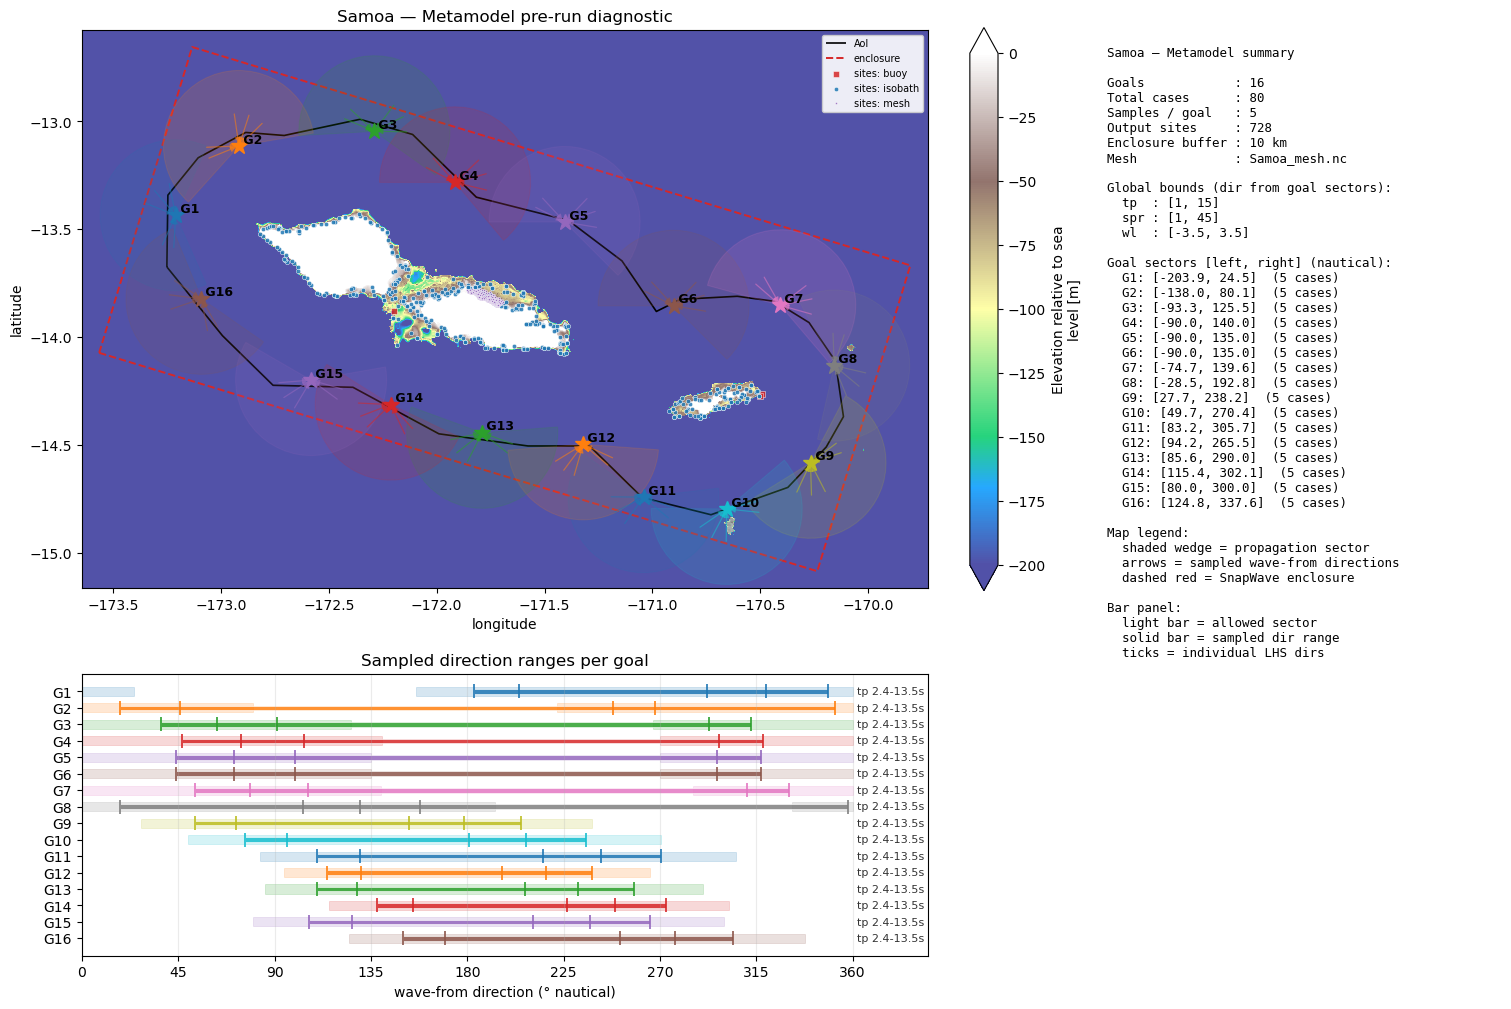

In [6]:
fig = wrapper.plot_configuration()
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [7]:
wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [8]:
# wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [9]:
wrapper.monitor_cases(value_counts="simple")

Status     
NOT STARTED    80
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: `hs`, `tp`, `dir` at output sites
- bottom row: domain `tripcolor` map (or overview fallback)
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted"})`.

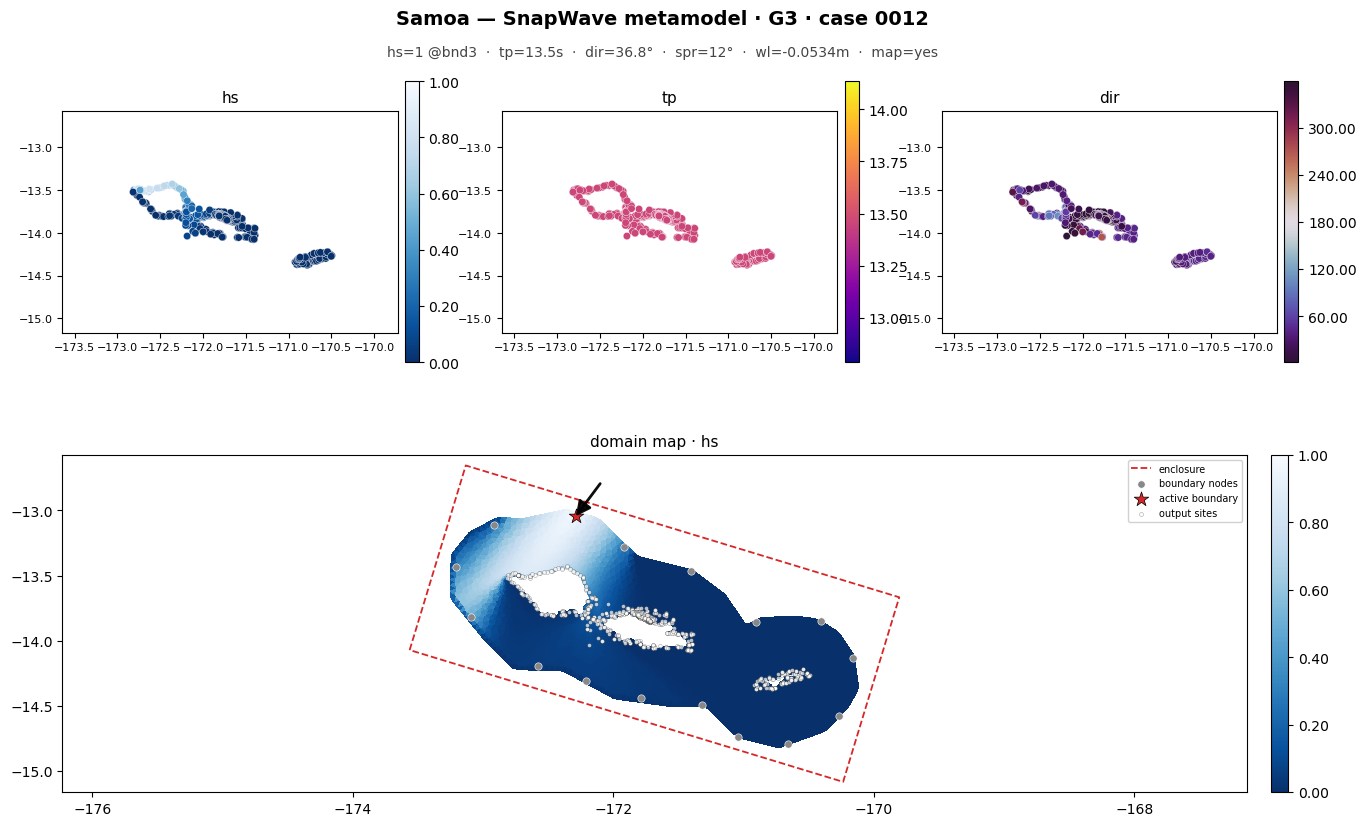

In [12]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted"}
)
wrapper.plot_case(goal=3, case_num=12, style=style);

In [49]:
wrapper.postprocess_cases()

'Done'